In [ ]:
#DETECÇÃO DE ANOMALIAS EM CONTRATOS ÚBLICOS DO PNCP
#OBJETIVO:
#Desenvolver e comparar métodos de detecção não supervisionada de anomalias para identificar contratos públicos atípicos no Estado de Mato Grosso.

#FONTE DOS DADOS:
#Dataset BR PNCP Public Procurement: Analytics, disponível no Kaggle e construído a partir dos dados públicos do Portal Nacional de Contratações Públicas.

#RECORTE DO PROJETO
#LOCALIZAÇÃO: Mato Grosso
#PERÍODO: 12 meses completos mais recentes disponíveis
#UNIDADE DE ANÁLISE: um contrato por registro
#ABORDAGEM: detecção não supervisionada de anomalias
#RESULTADO ESPERADO: ranking de contratos públicos atípicos para priorização de análise humana

#OBDERVAÇÃO METODOLÓGICA:
#Uma anomalia não representa automaticamente fraude ou irregularidade. Os resultados deste projeto devem ser interpretados como sinais de risco que exigem análise humana.

In [ ]:
!pip install -q kaggle pyarrow fastparquet

In [ ]:
import os
import sys
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Ambiente preparado com sucesso.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Pandas: 2.2.3
NumPy: 2.1.3
Ambiente preparado com sucesso.


In [ ]:
from google.colab import files

arquivos_enviados = files.upload()

Saving kaggle.json to kaggle (2).json


In [ ]:
from pathlib import Path
import shutil
import os

arquivo_origem = Path("/content/kaggle.json")
pasta_kaggle = Path.home() / ".kaggle"
arquivo_destino = pasta_kaggle / "kaggle.json"

if not arquivo_origem.exists():
    raise FileNotFoundError(
        "O arquivo kaggle.json não foi encontrado. "
        "Execute novamente a célula de upload e selecione o arquivo correto."
    )

pasta_kaggle.mkdir(parents=True, exist_ok=True)
shutil.copy2(arquivo_origem, arquivo_destino)
os.chmod(arquivo_destino, 0o600)

print("Credencial configurada em:", arquivo_destino)
print("Permissão aplicada com sucesso.")

Credencial configurada em: /root/.kaggle/kaggle.json
Permissão aplicada com sucesso.


In [ ]:
!kaggle datasets list -s "pncp analytics" --sort-by updated

ref                           title                                        size  lastUpdated                 downloadCount  voteCount  usabilityRating  
----------------------------  -------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
lucasrangelss/pncp-analytics  BR PNCP public procurement: Analytics  6206551221  2026-10-01 11:05:03.917000             28          4  0.9411765        


In [ ]:
from pathlib import Path

PASTA_PROJETO = Path("/content/projeto_pncp")
PASTA_DADOS_BRUTOS = PASTA_PROJETO / "dados_brutos"
PASTA_DADOS_TRATADOS = PASTA_PROJETO / "dados_tratados"
PASTA_RESULTADOS = PASTA_PROJETO / "resultados"
PASTA_GRAFICOS = PASTA_RESULTADOS / "graficos"
PASTA_MODELOS = PASTA_RESULTADOS / "modelos"

pastas = [
    PASTA_PROJETO,
    PASTA_DADOS_BRUTOS,
    PASTA_DADOS_TRATADOS,
    PASTA_RESULTADOS,
    PASTA_GRAFICOS,
    PASTA_MODELOS
]

for pasta in pastas:
    pasta.mkdir(parents=True, exist_ok=True)

print("Estrutura criada:")
for pasta in pastas:
    print("-", pasta)

Estrutura criada:
- /content/projeto_pncp
- /content/projeto_pncp/dados_brutos
- /content/projeto_pncp/dados_tratados
- /content/projeto_pncp/resultados
- /content/projeto_pncp/resultados/graficos
- /content/projeto_pncp/resultados/modelos


In [ ]:
!kaggle datasets files lucasrangelss/pncp-analytics



name                                                size  creationDate                
--------------------------------------------  ----------  --------------------------  
03_semantic_pncp.ipynb                              3568  2026-10-01 11:05:14.249000  
README.md                                            689  2026-10-01 11:05:14.239000  
audit.json                                          5649  2026-10-01 11:05:14.446000  
release_manifest.json                               2896  2026-10-01 11:05:14.289000  
schemas.json                                       25527  2026-10-01 11:05:14.259000  
semantic__obt_pncp_atas.parquet                 76861992  2026-10-01 11:05:16.112000  
semantic__obt_pncp_contratacoes.parquet        688781430  2026-10-01 11:05:38.910000  
semantic__obt_pncp_contratos.parquet           439036125  2026-10-01 11:05:26.942000  
semantic__obt_pncp_editais_semantico.parquet  5271446724  2026-10-01 11:07:20.536000  
semantic__obt_pncp_pca.parquet             

In [ ]:
import subprocess

comando = [
    "kaggle",
    "datasets",
    "files",
    "lucasrangelss/pncp-analytics"
]

resultado = subprocess.run(
    comando,
    capture_output=True,
    text=True,
    check=True
)

print(resultado.stdout)

name                                                size  creationDate                
--------------------------------------------  ----------  --------------------------  
03_semantic_pncp.ipynb                              3568  2026-10-01 11:05:14.249000  
README.md                                            689  2026-10-01 11:05:14.239000  
audit.json                                          5649  2026-10-01 11:05:14.446000  
release_manifest.json                               2896  2026-10-01 11:05:14.289000  
schemas.json                                       25527  2026-10-01 11:05:14.259000  
semantic__obt_pncp_atas.parquet                 76861992  2026-10-01 11:05:16.112000  
semantic__obt_pncp_contratacoes.parquet        688781430  2026-10-01 11:05:38.910000  
semantic__obt_pncp_contratos.parquet           439036125  2026-10-01 11:05:26.942000  
semantic__obt_pncp_editais_semantico.parquet  5271446724  2026-10-01 11:07:20.536000  
semantic__obt_pncp_pca.parquet             

In [ ]:
!pip install -q --upgrade kaggle

In [ ]:
!kaggle datasets download \
    -d lucasrangelss/pncp-analytics \
    -f semantic_obt_pncp_contratos.parquet \
    -p /content/projeto_pncp/dados_brutos \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/lucasrangelss/pncp-analytics
License(s): other
404 Client Error: Not Found for url: https://api.kaggle.com/v1/datasets.DatasetApiService/DownloadDataset


In [ ]:
%pip uninstall -y kaggle
%pip install -q --no-cache-dir --upgrade "kaggle>=2.2.2"

Found existing installation: kaggle 2.2.4
Uninstalling kaggle-2.2.4:
  Successfully uninstalled kaggle-2.2.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 23.5 MB/s eta 0:00:00


In [ ]:
!kaggle --version

Kaggle CLI 2.2.4


In [ ]:
from pathlib import Path

credencial = Path.home() / ".kaggle" / "kaggle.json"

if credencial.exists():
    print("Credencial do Kaggle encontrada.")
else:
    print("Credencial não encontrada. Será necessário enviar novamente o kaggle.json.")

Credencial do Kaggle encontrada.


In [ ]:
from pathlib import Path

PASTA_DADOS_BRUTOS = Path("/content/projeto_pncp/dados_brutos")
PASTA_DADOS_BRUTOS.mkdir(parents=True, exist_ok=True)

print("Pasta preparada:", PASTA_DADOS_BRUTOS)

Pasta preparada: /content/projeto_pncp/dados_brutos


In [ ]:
!kaggle datasets files lucasrangelss/pncp-analytics

name                                                size  creationDate                
--------------------------------------------  ----------  --------------------------  
03_semantic_pncp.ipynb                              3568  2026-10-01 11:05:14.249000  
README.md                                            689  2026-10-01 11:05:14.239000  
audit.json                                          5649  2026-10-01 11:05:14.446000  
release_manifest.json                               2896  2026-10-01 11:05:14.289000  
schemas.json                                       25527  2026-10-01 11:05:14.259000  
semantic__obt_pncp_atas.parquet                 76861992  2026-10-01 11:05:16.112000  
semantic__obt_pncp_contratacoes.parquet        688781430  2026-10-01 11:05:38.910000  
semantic__obt_pncp_contratos.parquet           439036125  2026-10-01 11:05:26.942000  
semantic__obt_pncp_editais_semantico.parquet  5271446724  2026-10-01 11:07:20.536000  
semantic__obt_pncp_pca.parquet             

In [ ]:
!kaggle datasets download \
    -d lucasrangelss/pncp-analytics \
    -f semantic_obt_pncp_contratos.parquet \
    -p /content/projeto_pncp/dados_brutos \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/lucasrangelss/pncp-analytics
License(s): other
404 Client Error: Not Found for url: https://api.kaggle.com/v1/datasets.DatasetApiService/DownloadDataset


In [ ]:
%pip install -q --upgrade kagglehub

In [ ]:
from pathlib import Path

credencial_kaggle = Path.home() / ".kaggle" / "kaggle.json"

if credencial_kaggle.exists():
    print("Credencial encontrada com sucesso.")
    print("Local:", credencial_kaggle)
else:
    print("Credencial não encontrada.")
    print("Será necessário enviar novamente o arquivo kaggle.json.")

Credencial encontrada com sucesso.
Local: /root/.kaggle/kaggle.json


In [19]:
import kagglehub

arquivo_baixado = kagglehub.dataset_download(
    "lucasrangelss/pncp-analytics",
    path="semantic_obt_pncp_contratos.parquet"
)

print("Download concluído.")
print("Arquivo armazenado em:")
print(arquivo_baixado)

KaggleApiHTTPError: 404 Client Error.

Resource not found at URL: https://kaggle.com/datasets/lucasrangelss/pncp-analytics/versions/1
Please make sure you specified the correct resource identifiers.

## Etapa 2: Localização ou Obtenção do Arquivo

Como a API do Kaggle está retornando erro 404 para este dataset, vamos verificar se o arquivo `semantic_obt_pncp_contratos.parquet` já foi carregado manualmente ou se está no Google Drive. Se não for encontrado, será necessário fazer o upload.

In [1]:
import os
import shutil
from pathlib import Path

NOME_ARQUIVO = "semantic_obt_pncp_contratos.parquet"
PASTA_DESTINO = Path("/content/projeto_pncp/dados_brutos")
PASTA_DESTINO.mkdir(parents=True, exist_ok=True)

def buscar_arquivo(nome_arquivo):
    print("Iniciando busca pelo arquivo...")
    # Busca recursiva a partir do /content
    for root, dirs, files in os.walk("/content"):
        # Ignorar pastas ocultas e de sistema para agilizar
        if any(ignored in root for ignored in ['.config', '.kaggle', 'sample_data']):
            continue
        if nome_arquivo in files:
            return Path(root) / nome_arquivo
    return None

caminho_encontrado = buscar_arquivo(NOME_ARQUIVO)

if caminho_encontrado:
    print(f"\n✅ Arquivo encontrado em: {caminho_encontrado}")

    # Validação da extensão
    if caminho_encontrado.suffix == '.parquet':
        print("✅ Extensão validada: .parquet")
    else:
        print("⚠️ Aviso: A extensão do arquivo não é .parquet")

    # Validação do tamanho
    tamanho_bytes = caminho_encontrado.stat().st_size
    tamanho_mb = tamanho_bytes / (1024 * 1024)
    print(f"✅ Tamanho do arquivo: {tamanho_mb:.2f} MB")

    # Cópia para a pasta dados_brutos se necessário
    destino_final = PASTA_DESTINO / NOME_ARQUIVO
    if caminho_encontrado.absolute() != destino_final.absolute():
        print(f"\nCopiando arquivo para a pasta de destino: {destino_final}")
        shutil.copy2(caminho_encontrado, destino_final)
        print("✅ Cópia concluída com sucesso.")
    else:
        print("\n✅ O arquivo já está no diretório correto de dados brutos.")
else:
    print(f"\n❌ O arquivo '{NOME_ARQUIVO}' não foi encontrado no ambiente.")
    print("\n--- AÇÃO NECESSÁRIA ---")
    print("Como o download automático falhou (Erro 404 da API do Kaggle),")
    print("por favor, realize o upload manual do arquivo para o Google Colab.")
    print("Você pode arrastar o arquivo para o painel de 'Arquivos' à esquerda,")
    print("ou montar o seu Google Drive caso o arquivo esteja lá.")
    print("Após o upload, execute esta célula novamente para que o arquivo seja validado e movido.")

Iniciando busca pelo arquivo...

❌ O arquivo 'semantic_obt_pncp_contratos.parquet' não foi encontrado no ambiente.

--- AÇÃO NECESSÁRIA ---
Como o download automático falhou (Erro 404 da API do Kaggle),
por favor, realize o upload manual do arquivo para o Google Colab.
Você pode arrastar o arquivo para o painel de 'Arquivos' à esquerda,
ou montar o seu Google Drive caso o arquivo esteja lá.
Após o upload, execute esta célula novamente para que o arquivo seja validado e movido.


### Correção do Download Automatizado

Identificamos que o arquivo no Kaggle está nomeado como `semantic__obt_pncp_contratos.parquet` (com dois underlines). Vamos baixar com o nome exato e ajustar para o padrão do nosso projeto. Isso garante que o pipeline funcione de ponta a ponta sem intervenção manual.

In [2]:
import os
from pathlib import Path

ARQUIVO_KAGGLE = "semantic__obt_pncp_contratos.parquet"
ARQUIVO_ESPERADO = "semantic_obt_pncp_contratos.parquet"
PASTA_DESTINO = Path("/content/projeto_pncp/dados_brutos")

print("Iniciando o download automatizado direto do Kaggle...")
!kaggle datasets download -d lucasrangelss/pncp-analytics -f {ARQUIVO_KAGGLE} -p {PASTA_DESTINO} --unzip

# Ajustando o nome do arquivo para o padrão definido no projeto
caminho_baixado = PASTA_DESTINO / ARQUIVO_KAGGLE
caminho_final = PASTA_DESTINO / ARQUIVO_ESPERADO

if caminho_baixado.exists():
    caminho_baixado.rename(caminho_final)
    print(f"\n✅ Arquivo baixado com sucesso e renomeado para: {caminho_final}")

    tamanho_mb = caminho_final.stat().st_size / (1024 * 1024)
    print(f"✅ Tamanho do arquivo: {tamanho_mb:.2f} MB")
elif caminho_final.exists():
    print(f"\n✅ Arquivo já existe e está pronto para uso: {caminho_final}")
else:
    print("\n❌ Ocorreu um problema no download. Verifique a conexão com a API.")


Iniciando o download automatizado direto do Kaggle...
Dataset URL: https://www.kaggle.com/datasets/lucasrangelss/pncp-analytics
License(s): other
100% 419M/419M [00:05<00:00, 82.3MB/s]


✅ Arquivo baixado com sucesso e renomeado para: /content/projeto_pncp/dados_brutos/semantic_obt_pncp_contratos.parquet
✅ Tamanho do arquivo: 418.70 MB


## Etapa 3: Inspeção Segura do Parquet

Nesta etapa, utilizamos a biblioteca `pyarrow.parquet` para inspecionar os metadados do arquivo sem precisar carregá-lo completamente na memória RAM. Vamos extrair:
- Quantidade de linhas e colunas;
- Quantidade de *row groups* (partições internas);
- Nomes e tipos das colunas;
- Estimativa de uso de memória;
- Uma pequena amostra para verificar a integridade visual.

In [3]:
import pyarrow.parquet as pq
import pandas as pd

ARQUIVO_PARQUET = PASTA_DESTINO / "semantic_obt_pncp_contratos.parquet"

print("Iniciando a leitura dos metadados...")
# Lendo apenas os metadados do arquivo
metadados = pq.read_metadata(ARQUIVO_PARQUET)

num_linhas = metadados.num_rows
num_colunas = metadados.num_columns
num_row_groups = metadados.num_row_groups

print("\n--- RESUMO DOS METADADOS ---")
print(f"Linhas totais: {num_linhas:,}")
print(f"Colunas totais: {num_colunas}")
print(f"Grupos internos (row groups): {num_row_groups}")

# Estimativa simples de memória (tamanho do arquivo não reflete RAM exata, mas metadados ajudam)
# Um valor base conservador é considerar 8 a 16 bytes por célula em média para dados mistos
estimativa_memoria_mb = (num_linhas * num_colunas * 8) / (1024 * 1024)
print(f"Uso de memória estimado para carregar tudo (mínimo conservador): ~{estimativa_memoria_mb:.2f} MB")

print("\n--- ESQUEMA DE COLUNAS (Nomes e Tipos) ---")
schema = metadados.schema
for i, nome in enumerate(schema.names):
    tipo = schema.column(i).physical_type
    print(f"{nome}: {tipo}")

print("\n--- AMOSTRA INICIAL ---")
# Carregando apenas uma amostra segura para verificar se o arquivo está íntegro
# PyArrow permite ler partes específicas, mas pandas.read_parquet tem nrows dependendo da engine.
# Vamos usar PyArrow para ler apenas o primeiro batch/row_group e converter para pandas
amostra_tabela = pq.read_table(ARQUIVO_PARQUET)
amostra_df = amostra_tabela.slice(0, 5).to_pandas()
display(amostra_df)

print("\n✅ Inspeção de metadados e amostra inicial concluídas com sucesso. O arquivo parece íntegro.")


Iniciando a leitura dos metadados...

--- RESUMO DOS METADADOS ---
Linhas totais: 3,428,193
Colunas totais: 54
Grupos internos (row groups): 6712
Uso de memória estimado para carregar tudo (mínimo conservador): ~1412.37 MB

--- ESQUEMA DE COLUNAS (Nomes e Tipos) ---
numero_controle_pncp: BYTE_ARRAY
numero_controle_pncp_compra: BYTE_ARRAY
numero_controle_pncp_ata: BYTE_ARRAY
ano_contrato: INT64
numero_contrato_empenho: BYTE_ARRAY
sequencial_contrato: INT64
processo: BYTE_ARRAY
tipo_contrato_id: INT64
tipo_contrato_nome: BYTE_ARRAY
categoria_processo_id: INT64
categoria_processo_nome: BYTE_ARRAY
data_assinatura: INT32
data_vigencia_inicio: INT32
data_vigencia_fim: INT32
data_publicacao_pncp: INT64
data_atualizacao: INT64
data_atualizacao_global: INT64
ni_fornecedor: BYTE_ARRAY
tipo_pessoa: BYTE_ARRAY
nome_razao_social_fornecedor: BYTE_ARRAY
codigo_pais_fornecedor: BYTE_ARRAY
ni_fornecedor_subcontratado: BYTE_ARRAY
nome_fornecedor_subcontratado: BYTE_ARRAY
tipo_pessoa_subcontratada: BYTE_

,numero_controle_pncp,numero_controle_pncp_compra,numero_controle_pncp_ata,ano_contrato,numero_contrato_empenho,sequencial_contrato,processo,tipo_contrato_id,tipo_contrato_nome,categoria_processo_id,...,emenda_parlamentar,identificador_cipi,url_cipi,usuario_nome,codigo_municipio,nome_municipio,sigla_uf,nome_uf,nome_regiao,codigo_uf
0,00059311000126-2-000094/2021,00059311000126-1-000046/2021,None,2021,2021NE000109,94,08750.000408/2021-43,7,Empenho,8,...,None,None,None,Contratos.gov.br,1100049,Cacoal,RO,Rondônia,Norte,11
1,00059311000126-2-000016/2022,00059311000126-1-000018/2022,None,2022,2022NE000026,16,08750.000085/2022-79,7,Empenho,8,...,None,None,None,Contratos.gov.br,1100049,Cacoal,RO,Rondônia,Norte,11
2,00059311000126-2-000015/2022,00059311000126-1-000005/2022,None,2022,2022NE000024,15,08750.000056/2022-15,7,Empenho,8,...,None,None,None,Contratos.gov.br,1100049,Cacoal,RO,Rondônia,Norte,11
3,00059311000126-2-000013/2022,00059311000126-1-000018/2022,None,2022,2022NE000023,13,08750.000085/2022-79,7,Empenho,8,...,None,None,None,Contratos.gov.br,1100049,Cacoal,RO,Rondônia,Norte,11
4,00059311000126-2-000017/2022,00059311000126-1-000005/2022,None,2022,2022NE000025,17,08750.000056/2022-15,7,Empenho,8,...,None,None,None,Contratos.gov.br,1100049,Cacoal,RO,Rondônia,Norte,11



✅ Inspeção de metadados e amostra inicial concluídas com sucesso. O arquivo parece íntegro.


## Etapa 4: Dicionário Inicial de Dados

Nesta etapa, construiremos um dicionário de dados avaliando a completude e os tipos das colunas. O dicionário final será exportado em CSV para documentação. Ao fim, liberaremos a memória para garantir estabilidade.

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import os

# Redefinindo os caminhos necessários
PASTA_PROJETO = Path("/content/projeto_pncp")
PASTA_DESTINO = PASTA_PROJETO / "dados_brutos"
PASTA_RESULTADOS = PASTA_PROJETO / "resultados"
ARQUIVO_PARQUET = PASTA_DESTINO / "semantic_obt_pncp_contratos.parquet"

# Verificação defensiva: se o arquivo sumiu (ex: reinício de sessão), baixa de novo
if not ARQUIVO_PARQUET.exists():
    print("Arquivo não encontrado (possível limpeza de sessão). Iniciando re-download...")
    PASTA_DESTINO.mkdir(parents=True, exist_ok=True)
    os.system(f"kaggle datasets download -d lucasrangelss/pncp-analytics -f semantic__obt_pncp_contratos.parquet -p {PASTA_DESTINO} --unzip")

    arquivo_baixado = PASTA_DESTINO / "semantic__obt_pncp_contratos.parquet"
    if arquivo_baixado.exists():
        arquivo_baixado.rename(ARQUIVO_PARQUET)
        print("Download e renomeação concluídos com sucesso.")
    else:
        raise FileNotFoundError("Falha ao recuperar o arquivo. Verifique a API do Kaggle.")

print("Carregando a base de dados completa em memória (isso pode levar cerca de 1 minuto)...")
df_full = pd.read_parquet(ARQUIVO_PARQUET, engine='pyarrow')

print("Calculando estatísticas para o dicionário de dados...")

dic_dados = []

for col in df_full.columns:
    tipo = str(df_full[col].dtype)
    pct_ausente = (df_full[col].isna().sum() / len(df_full)) * 100
    qtd_unicos = df_full[col].nunique()
    exemplo = df_full[col].dropna().iloc[0] if not df_full[col].dropna().empty else None

    # Regra simples de inferência inicial
    if "id" in col.lower() or "numero" in col.lower():
        funcao_analitica = "Identificador"
    elif "data" in col.lower():
        funcao_analitica = "Data/Tempo"
    elif np.issubdtype(df_full[col].dtype, np.number):
        funcao_analitica = "Métrica"
    else:
        funcao_analitica = "Categoria/Texto"

    acao = "Manter" if pct_ausente < 90 else "Avaliar descarte"

    dic_dados.append({
        "nome_da_coluna": col,
        "tipo_original": tipo,
        "percentual_ausentes": round(pct_ausente, 2),
        "quantidade_unicos": qtd_unicos,
        "exemplo_valor": exemplo,
        "funcao_analitica": funcao_analitica,
        "indicacao": acao
    })

df_dicionario = pd.DataFrame(dic_dados)

# Exibindo o dicionário
display(df_dicionario)

# Exportando para CSV
pasta_tabelas = PASTA_RESULTADOS / "tabelas"
pasta_tabelas.mkdir(parents=True, exist_ok=True)
caminho_dicionario = pasta_tabelas / "dicionario_dados_inicial.csv"
df_dicionario.to_csv(caminho_dicionario, index=False, sep=";")

print(f"\n✅ Dicionário de dados gerado e exportado com sucesso para: {caminho_dicionario}")

# Liberação de memória
del df_full
import gc
gc.collect()
print("Memória da base completa liberada para as próximas etapas.")

Arquivo não encontrado (possível limpeza de sessão). Iniciando re-download...
Download e renomeação concluídos com sucesso.
Carregando a base de dados completa em memória (isso pode levar cerca de 1 minuto)...
Calculando estatísticas para o dicionário de dados...


,nome_da_coluna,tipo_original,percentual_ausentes,quantidade_unicos,exemplo_valor,funcao_analitica,indicacao
0,numero_controle_pncp,object,0.00,3428193,00059311000126-2-000094/2021,Identificador,Manter
1,numero_controle_pncp_compra,object,0.00,1205848,00059311000126-1-000046/2021,Identificador,Manter
2,numero_controle_pncp_ata,object,91.55,54022,04012548000102-1-000015/2026-000001,Identificador,Avaliar descarte
3,ano_contrato,int64,0.00,46,2021,Métrica,Manter
4,numero_contrato_empenho,object,0.00,1088175,2021NE000109,Identificador,Manter
5,sequencial_contrato,int64,0.00,40034,94,Métrica,Manter
6,processo,object,0.00,856490,08750.000408/2021-43,Categoria/Texto,Manter
7,tipo_contrato_id,int64,0.00,12,7,Identificador,Manter
8,tipo_contrato_nome,object,0.00,12,Empenho,Categoria/Texto,Manter
9,categoria_processo_id,int64,0.00,11,8,Identificador,Manter



✅ Dicionário de dados gerado e exportado com sucesso para: /content/projeto_pncp/resultados/tabelas/dicionario_dados_inicial.csv
Memória da base completa liberada para as próximas etapas.


## Etapa 5: Identificação do Recorte Geográfico

O objetivo desta etapa é selecionar os contratos públicos realizados no Estado de Mato Grosso (MT). Para garantir que estamos avaliando órgãos contratantes do estado (e não apenas fornecedores localizados lá), utilizaremos a coluna `unidade_uf_sigla`.

Faremos uma contagem de registros por UF, identificaremos o volume de contratos de MT e o seu percentual em relação ao Brasil inteiro. Após isso, criaremos uma base filtrada mais leve apenas com os dados de interesse.

In [3]:
import pandas as pd
from pathlib import Path

PASTA_PROJETO = Path("/content/projeto_pncp")
ARQUIVO_PARQUET = PASTA_PROJETO / "dados_brutos" / "semantic_obt_pncp_contratos.parquet"
PASTA_TRATADOS = PASTA_PROJETO / "dados_tratados"
PASTA_TRATADOS.mkdir(parents=True, exist_ok=True)

print("Carregando apenas a coluna geográfica para análise (economia de memória)...")
df_geo = pd.read_parquet(ARQUIVO_PARQUET, columns=['unidade_uf_sigla'], engine='pyarrow')

# Análise de distribuição por UF
total_registros = len(df_geo)
contagem_uf = df_geo['unidade_uf_sigla'].value_counts(dropna=False)

print("\n--- DISTRIBUIÇÃO DE CONTRATOS POR UF (TOP 10) ---")
display(contagem_uf.head(10))

# Isolando os dados de Mato Grosso (MT)
registros_mt = contagem_uf.get('MT', 0)
percentual_mt = (registros_mt / total_registros) * 100

print("\n--- RESUMO DO RECORTE (MATO GROSSO) ---")
print(f"Total de registros no Brasil: {total_registros:,}")
print(f"Contratos em Mato Grosso (MT): {registros_mt:,}")
print(f"Representatividade de MT: {percentual_mt:.2f}%")

# Liberando a coluna isolada da memória
del df_geo

if registros_mt > 0:
    print("\nCarregando todas as colunas apenas para o estado de Mato Grosso...")
    # Lendo o parquet aplicando filtro direto (pyarrow permite pushdown predicate, economizando muita RAM)
    df_mt = pd.read_parquet(
        ARQUIVO_PARQUET,
        engine='pyarrow',
        filters=[('unidade_uf_sigla', '=', 'MT')]
    )

    # Salvando a base filtrada para as próximas etapas
    arquivo_mt_parquet = PASTA_TRATADOS / "contratos_mt_bruto.parquet"
    df_mt.to_parquet(arquivo_mt_parquet, engine='pyarrow', index=False)

    print(f"\n✅ Base de Mato Grosso filtrada e salva com sucesso em: {arquivo_mt_parquet}")
    print(f"Dimensões da base MT: {df_mt.shape[0]} linhas e {df_mt.shape[1]} colunas.")
else:
    print("\n❌ Nenhum registro encontrado para Mato Grosso (MT). Verifique a base de dados.")


Carregando apenas a coluna geográfica para análise (economia de memória)...

--- DISTRIBUIÇÃO DE CONTRATOS POR UF (TOP 10) ---


,count
unidade_uf_sigla,
SC,913178
SP,619038
MG,277738
RS,265886
GO,235742
PR,176555
BA,150346
CE,142135
RJ,114538



--- RESUMO DO RECORTE (MATO GROSSO) ---
Total de registros no Brasil: 3,428,193
Contratos em Mato Grosso (MT): 23,499
Representatividade de MT: 0.69%

Carregando todas as colunas apenas para o estado de Mato Grosso...

✅ Base de Mato Grosso filtrada e salva com sucesso em: /content/projeto_pncp/dados_tratados/contratos_mt_bruto.parquet
Dimensões da base MT: 23499 linhas e 54 colunas.


## Etapa 6: Escolha da Coluna de Data

Nesta etapa, vamos avaliar todas as colunas que representam datas para decidir qual usaremos como referência temporal do projeto. Verificaremos a completude, os valores mínimos e máximos, e os tipos de dados.

Prioridade para a escolha:
1. Data de assinatura;
2. Data de publicação;
3. Data de inclusão/atualização.

In [4]:
import pandas as pd

# Já temos df_mt na memória, vamos identificar as colunas de data
colunas_data = [col for col in df_mt.columns if 'data' in col.lower() or 'ano' in col.lower()]

print("--- AVALIAÇÃO DE COLUNAS DE DATA EM MATO GROSSO ---")

resumo_datas = []

for col in colunas_data:
    # Criar uma cópia temporária da coluna para tentar converter para datetime
    # usando 'coerce' para transformar erros em NaT
    if 'ano' in col.lower() and 'data' not in col.lower():
        # Para a coluna ano_contrato, é apenas o ano
        s_date = pd.to_datetime(df_mt[col], format='%Y', errors='coerce')
    else:
        # Para o resto que é formato data ou timestamp
        if df_mt[col].dtype == 'int32':
            # Às vezes datas no parquet int32 vêm como dias desde a epoch (1970-01-01), vamos tentar decodificar
            s_date = pd.to_datetime(df_mt[col], unit='D', origin='unix', errors='coerce')
        else:
            s_date = pd.to_datetime(df_mt[col], errors='coerce')

    total_registros = len(df_mt)
    n_ausentes_original = df_mt[col].isna().sum()
    n_validos = s_date.notna().sum()
    pct_valido = (n_validos / total_registros) * 100
    pct_ausente_original = (n_ausentes_original / total_registros) * 100

    data_min = s_date.min() if n_validos > 0 else None
    data_max = s_date.max() if n_validos > 0 else None

    resumo_datas.append({
        "Coluna": col,
        "Tipo original": str(df_mt[col].dtype),
        "% Ausente Original": round(pct_ausente_original, 2),
        "% Data Válida": round(pct_valido, 2),
        "Mínimo": data_min.strftime('%Y-%m-%d') if pd.notnull(data_min) else None,
        "Máximo": data_max.strftime('%Y-%m-%d') if pd.notnull(data_max) else None
    })

df_resumo_datas = pd.DataFrame(resumo_datas)
display(df_resumo_datas)

print("\nAnalisando a viabilidade da data de assinatura e publicação...")

# Convertendo a data de assinatura e publicacao_pncp para avaliar a distribuição
# Vamos observar se o formato das colunas que vieram como int32 faz sentido na conversão.
df_mt['data_assinatura_dt'] = pd.to_datetime(df_mt['data_assinatura'], unit='D', origin='unix', errors='coerce')
df_mt['data_publicacao_pncp_dt'] = pd.to_datetime(df_mt['data_publicacao_pncp'], errors='coerce').dt.tz_localize(None)

print("Amostra de datas convertidas:")
display(df_mt[['data_assinatura', 'data_assinatura_dt', 'data_publicacao_pncp', 'data_publicacao_pncp_dt']].head())


--- AVALIAÇÃO DE COLUNAS DE DATA EM MATO GROSSO ---


,Coluna,Tipo original,% Ausente Original,% Data Válida,Mínimo,Máximo
0,ano_contrato,int64,0.0,100.0,2021-01-01,2026-01-01
1,data_assinatura,object,0.0,100.0,2021-10-04,2026-09-29
2,data_vigencia_inicio,object,0.0,100.0,2021-10-04,2031-07-13
3,data_vigencia_fim,object,0.1,99.9,2021-12-31,2206-08-12
4,data_publicacao_pncp,"datetime64[us, UTC]",0.0,100.0,2021-10-05,2026-09-30
5,data_atualizacao,"datetime64[us, UTC]",0.0,100.0,2021-10-05,2026-09-30
6,data_atualizacao_global,"datetime64[us, UTC]",0.0,100.0,2021-10-05,2026-09-30



Analisando a viabilidade da data de assinatura e publicação...
Amostra de datas convertidas:


,data_assinatura,data_assinatura_dt,data_publicacao_pncp,data_publicacao_pncp_dt
0,2022-03-11,NaT,2022-03-14 10:43:02+00:00,2022-03-14 10:43:02
1,2022-03-10,NaT,2022-03-14 10:43:28+00:00,2022-03-14 10:43:28
2,2022-09-06,NaT,2022-09-09 14:59:39+00:00,2022-09-09 14:59:39
3,2022-12-28,NaT,2022-12-29 12:35:56+00:00,2022-12-29 12:35:56
4,2022-03-11,NaT,2022-03-14 10:43:01+00:00,2022-03-14 10:43:01


## Etapa 7: Definição dos 12 meses completos mais recentes

Com a `data_assinatura` escolhida, vamos estabelecer nossa janela de análise. O processo consiste em:
1. Converter a data corretamente.
2. Identificar a data máxima disponível.
3. Avaliar se o mês da data máxima está completo (ex: vai até o dia 30 ou 31).
4. Definir o último mês completo e contar 12 meses para trás.
5. Aplicar o recorte temporal à base de dados.

In [5]:
import pandas as pd
from dateutil.relativedelta import relativedelta
import calendar

# 1. Corrigindo a conversão da data escolhida
df_mt['data_assinatura_dt'] = pd.to_datetime(df_mt['data_assinatura'], errors='coerce')

# 2. Identificando a data máxima válida
data_maxima = df_mt['data_assinatura_dt'].max()

print(f"Data máxima identificada no dataset: {data_maxima.strftime('%Y-%m-%d')}")

# 3. Avaliando se o último mês está completo
ultimo_dia_do_mes = calendar.monthrange(data_maxima.year, data_maxima.month)[1]
mes_completo = data_maxima.day == ultimo_dia_do_mes

if mes_completo:
    print(f"O mês {data_maxima.strftime('%m/%Y')} está completo.")
    data_fim_janela = data_maxima
else:
    print(f"O mês {data_maxima.strftime('%m/%Y')} está incompleto (vai apenas até o dia {data_maxima.day}).")
    print("Descartando o mês incompleto da janela principal...")
    # Retroceder para o último dia do mês anterior
    data_fim_janela = data_maxima.replace(day=1) - pd.Timedelta(days=1)

# 4. Definindo a janela de 12 meses fechados
# Se data_fim_janela é 31/08/2026, a data inicial deve ser 01/09/2025
data_inicio_janela = (data_fim_janela.replace(day=1) - relativedelta(months=11))

print("\n--- RECORTE TEMPORAL DEFINIDO ---")
print(f"Data de Início: {data_inicio_janela.strftime('%Y-%m-%d')}")
print(f"Data de Término: {data_fim_janela.strftime('%Y-%m-%d')}")

# 5. Filtrando a base de dados
mascara_periodo = (df_mt['data_assinatura_dt'] >= data_inicio_janela) & (df_mt['data_assinatura_dt'] <= data_fim_janela)
df_mt_12m = df_mt[mascara_periodo].copy()

# 6. Exibindo a distribuição de contratos por mês no período selecionado
df_mt_12m['ano_mes'] = df_mt_12m['data_assinatura_dt'].dt.to_period('M')
distribuicao_meses = df_mt_12m['ano_mes'].value_counts().sort_index()

print(f"\nQuantidade de contratos na janela de 12 meses: {len(df_mt_12m)}")
print("\nDistribuição por mês:")
display(distribuicao_meses)

print("\n✅ Recorte temporal validado. Base pronta para a etapa de limpeza e qualidade.")

Data máxima identificada no dataset: 2026-09-29
O mês 09/2026 está incompleto (vai apenas até o dia 29).
Descartando o mês incompleto da janela principal...

--- RECORTE TEMPORAL DEFINIDO ---
Data de Início: 2025-09-01
Data de Término: 2026-08-31

Quantidade de contratos na janela de 12 meses: 9021

Distribuição por mês:


,count
ano_mes,
2025-09,919
2025-10,874
2025-11,777
2025-12,893
2026-01,538
2026-02,642
2026-03,682
2026-04,573
2026-05,509



✅ Recorte temporal validado. Base pronta para a etapa de limpeza e qualidade.


## Etapa 8: Limpeza e Qualidade dos Dados

Aqui removeremos colunas com baixo preenchimento, metadados irrelevantes para detecção de anomalias e variáveis com variância zero (ex: estado, região). Em seguida, tratamos os valores ausentes para que a base fique 100% preenchida e pronta para a extração de características (Feature Engineering).

In [7]:
import pandas as pd
from pathlib import Path

PASTA_PROJETO = Path("/content/projeto_pncp")
PASTA_TRATADOS = PASTA_PROJETO / "dados_tratados"

# 1. Identificar colunas com mais de 90% de dados nulos
limite_nulos = len(df_mt_12m) * 0.90
colunas_com_muitos_nulos = df_mt_12m.columns[df_mt_12m.isna().sum() > limite_nulos].tolist()

# 2. Definir colunas redundantes ou sem valor analítico (variância zero ou admin)
colunas_remover_manuais = [
    'unidade_uf_sigla', 'unidade_uf_nome', 'sigla_uf', 'nome_uf', 'nome_regiao', 'codigo_uf', # Tudo já é MT
    'data_atualizacao', 'data_atualizacao_global', 'usuario_nome', 'url_cipi', 'identificador_cipi',
    'ano_mes', 'data_assinatura_dt', 'data_publicacao_pncp_dt' # Colunas auxiliares da etapa anterior
]

colunas_para_remover = list(set(colunas_com_muitos_nulos + colunas_remover_manuais))
colunas_para_remover = [c for c in colunas_para_remover if c in df_mt_12m.columns]

df_clean = df_mt_12m.drop(columns=colunas_para_remover).copy()

# 3. Tratamento de Valores Faltantes
cols_numericas = df_clean.select_dtypes(include=['float64', 'int64', 'int32']).columns
cols_categoricas = df_clean.select_dtypes(include=['object', 'category']).columns

# Preenchendo numéricas nulas com 0
for col in cols_numericas:
    df_clean[col] = df_clean[col].fillna(0)

# Preenchendo texto nulo com 'Não Informado' e forçando tipo string
for col in cols_categoricas:
    df_clean[col] = df_clean[col].fillna('Não Informado').astype(str)

print(f"Colunas removidas ({len(colunas_para_remover)}):")
print(", ".join(colunas_para_remover))

print(f"\nDimensão final da base tratada: {df_clean.shape}")

total_nulos = df_clean.isna().sum().sum()
print(f"Total de valores nulos na base após limpeza: {total_nulos}")

# 4. Salvar base limpa para a próxima etapa
caminho_base_limpa = PASTA_TRATADOS / "contratos_mt_12m_limpo.parquet"
df_clean.to_parquet(caminho_base_limpa, index=False)
print(f"\n✅ Base tratada e salva com sucesso em: {caminho_base_limpa}")

Colunas removidas (19):
data_atualizacao, data_atualizacao_global, nome_uf, ano_mes, data_assinatura_dt, numero_controle_pncp_ata, ni_fornecedor_subcontratado, emenda_parlamentar, data_publicacao_pncp_dt, unidade_uf_sigla, url_cipi, usuario_nome, sigla_uf, identificador_cipi, unidade_uf_nome, codigo_uf, nome_fornecedor_subcontratado, nome_regiao, tipo_pessoa_subcontratada

Dimensão final da base tratada: (9021, 38)
Total de valores nulos na base após limpeza: 0

✅ Base tratada e salva com sucesso em: /content/projeto_pncp/dados_tratados/contratos_mt_12m_limpo.parquet


## Etapa 9: Engenharia de Atributos (Feature Engineering)

Criação de novas variáveis baseadas no conhecimento do negócio (licitações) que podem ajudar os algoritmos não supervisionados a encontrar padrões anômalos. Focaremos principalmente em variáveis de tempo e financeiras.

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

PASTA_TRATADOS = Path("/content/projeto_pncp/dados_tratados")
caminho_base_limpa = PASTA_TRATADOS / "contratos_mt_12m_limpo.parquet"

print("Carregando a base limpa...")
df_features = pd.read_parquet(caminho_base_limpa)

# 1. Transformações de Tempo (Vigência)
# Como forçamos tudo para string na etapa anterior, vamos converter temporariamente para datetime
df_features['dt_inicio'] = pd.to_datetime(df_features['data_vigencia_inicio'], errors='coerce')
df_features['dt_fim'] = pd.to_datetime(df_features['data_vigencia_fim'], errors='coerce')

# Calculando a duração em dias (lidando com nulos/NaT criando valor -1 ou preenchendo com a mediana posteriormente)
df_features['tempo_vigencia_dias'] = (df_features['dt_fim'] - df_features['dt_inicio']).dt.days
df_features['tempo_vigencia_dias'] = df_features['tempo_vigencia_dias'].fillna(-1)

# Limpando as colunas temporárias de datetime
df_features = df_features.drop(columns=['dt_inicio', 'dt_fim'])

# 2. Transformações Financeiras
# Diferença de valor (ex: aditivos)
df_features['valor_aditivado'] = df_features['valor_global'] - df_features['valor_inicial']

# Evitar divisão por zero na proporção
df_features['proporcao_parcela_global'] = np.where(
    df_features['valor_global'] > 0,
    df_features['valor_parcela'] / df_features['valor_global'],
    0
)

# Criar log do valor global para reduzir o viés de valores extremos (outliers naturais)
# Adicionamos 1 para evitar log(0)
df_features['log_valor_global'] = np.log1p(df_features['valor_global'].clip(lower=0))

print("\n--- RESUMO DAS NOVAS VARIÁVEIS ---")
display(df_features[['tempo_vigencia_dias', 'valor_aditivado', 'proporcao_parcela_global', 'log_valor_global']].describe())

# 3. Salvar a base com as features
caminho_base_features = PASTA_TRATADOS / "contratos_mt_12m_features.parquet"
df_features.to_parquet(caminho_base_features, index=False)

print(f"\n✅ Base com novas features salva em: {caminho_base_features}")
print(f"Total de colunas agora: {df_features.shape[1]}")

Carregando a base limpa...

--- RESUMO DAS NOVAS VARIÁVEIS ---


,tempo_vigencia_dias,valor_aditivado,proporcao_parcela_global,log_valor_global
count,9021.000000,9.021000e+03,9021.000000,9021.000000
mean,329.650261,2.257612e+04,0.642473,8.275259
std,471.520702,2.042173e+06,1.153033,4.673072
min,-1.000000,-4.840287e+07,0.000000,0.000000
25%,122.000000,0.000000e+00,0.000000,6.502190
50%,364.000000,0.000000e+00,1.000000,9.280193
75%,365.000000,0.000000e+00,1.000000,11.339940
max,27444.000000,9.395097e+07,100.000000,22.592552



✅ Base com novas features salva em: /content/projeto_pncp/dados_tratados/contratos_mt_12m_features.parquet
Total de colunas agora: 42


## Etapa 10: Modelagem e Detecção de Anomalias

Aplicação do modelo não supervisionado `Isolation Forest`. O modelo avaliará as *features* construídas e atribuirá um *score* de atipicidade para cada contrato público. Contratos com os menores *scores* serão classificados como anomalias potenciais.

In [9]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

PASTA_TRATADOS = Path("/content/projeto_pncp/dados_tratados")
PASTA_RESULTADOS = Path("/content/projeto_pncp/resultados/modelos")
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

caminho_base_features = PASTA_TRATADOS / "contratos_mt_12m_features.parquet"
df_model = pd.read_parquet(caminho_base_features)

# 1. Seleção das Features para o Modelo
# Vamos usar as features numéricas criadas e algumas originais importantes
colunas_modelo = [
    'tempo_vigencia_dias',
    'valor_aditivado',
    'proporcao_parcela_global',
    'log_valor_global',
    'numero_retificacao'
]

# Preparando os dados (X)
X = df_model[colunas_modelo].copy()

# 2. Padronização dos Dados
# Modelos baseados em distância/isolamento se beneficiam de dados na mesma escala
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Treinamento do Isolation Forest
# contamination=0.05 significa que esperamos que 5% da base seja anômala (taxa de corte)
modelo_if = IsolationForest(n_estimators=200, contamination=0.05, random_state=42, n_jobs=-1)
modelo_if.fit(X_scaled)

# 4. Previsões e Scores
# predict() retorna 1 para normal, -1 para anomalia
previsoes = modelo_if.predict(X_scaled)

# decision_function() retorna o score (valores menores/negativos são mais anômalos)
scores = modelo_if.decision_function(X_scaled)

# 5. Acoplando os resultados à base original
df_model['is_anomalia'] = np.where(previsoes == -1, 'Sim', 'Não')
df_model['score_anomalia'] = scores

# 6. Ordenando os resultados pelo risco (do mais anômalo para o menos)
df_scored = df_model.sort_values(by='score_anomalia', ascending=True).reset_index(drop=True)

# 7. Resumo dos resultados
qtd_anomalias = len(df_scored[df_scored['is_anomalia'] == 'Sim'])
print("--- RESULTADOS DA DETECÇÃO DE ANOMALIAS ---")
print(f"Total de contratos analisados: {len(df_scored)}")
print(f"Contratos sinalizados como anomalias (5%): {qtd_anomalias}")

print("\n--- TOP 5 CONTRATOS MAIS ATÍPICOS ---")
colunas_exibicao = ['numero_controle_pncp', 'nome_razao_social_fornecedor', 'objeto_contrato', 'valor_global', 'score_anomalia']
display(df_scored[df_scored['is_anomalia'] == 'Sim'][colunas_exibicao].head(5))

# 8. Salvando a base final 'escorada'
caminho_base_escorada = PASTA_RESULTADOS / "contratos_mt_12m_scored.parquet"
df_scored.to_parquet(caminho_base_escorada, index=False)
print(f"\n✅ Base com scores de anomalia salva em: {caminho_base_escorada}")

--- RESULTADOS DA DETECÇÃO DE ANOMALIAS ---
Total de contratos analisados: 9021
Contratos sinalizados como anomalias (5%): 451

--- TOP 5 CONTRATOS MAIS ATÍPICOS ---


,numero_controle_pncp,nome_razao_social_fornecedor,objeto_contrato,valor_global,score_anomalia
0,03533064000146-2-000168/2025,BANCO DO BRASIL S.A.,Centralização pelo contratante no Banco do Bra...,81000000.00,-0.182255
1,58290502000184-2-000002/2026,BANCO ITAÚ UNIBANCO S/A,Contratação de serviço especializado d...,64794556.21,-0.173937
2,03533064000146-2-000340/2026,HBENTO SERVIÇOS EM SAUDE,Credenciamento de pessoas jurídicas para ...,13173221.23,-0.153963
3,03533064000146-2-000301/2026,HOSPITAL OTORRINO LTDA,Credenciamento de pessoas jurídicas para ...,13264744.26,-0.153963
4,03533064000146-2-000328/2026,SANTA MARIA EMPREENDIMENTOS E PARTICIPAÇÕES S/A,O objeto do presente contrato é a locaç...,15360000.00,-0.150188



✅ Base com scores de anomalia salva em: /content/projeto_pncp/resultados/modelos/contratos_mt_12m_scored.parquet


## Etapa 11: Visualização dos Resultados

Geração de gráficos para facilitar a interpretação dos resultados do modelo de detecção de anomalias. Analisaremos a separação dos scores e o comportamento das variáveis mais importantes.

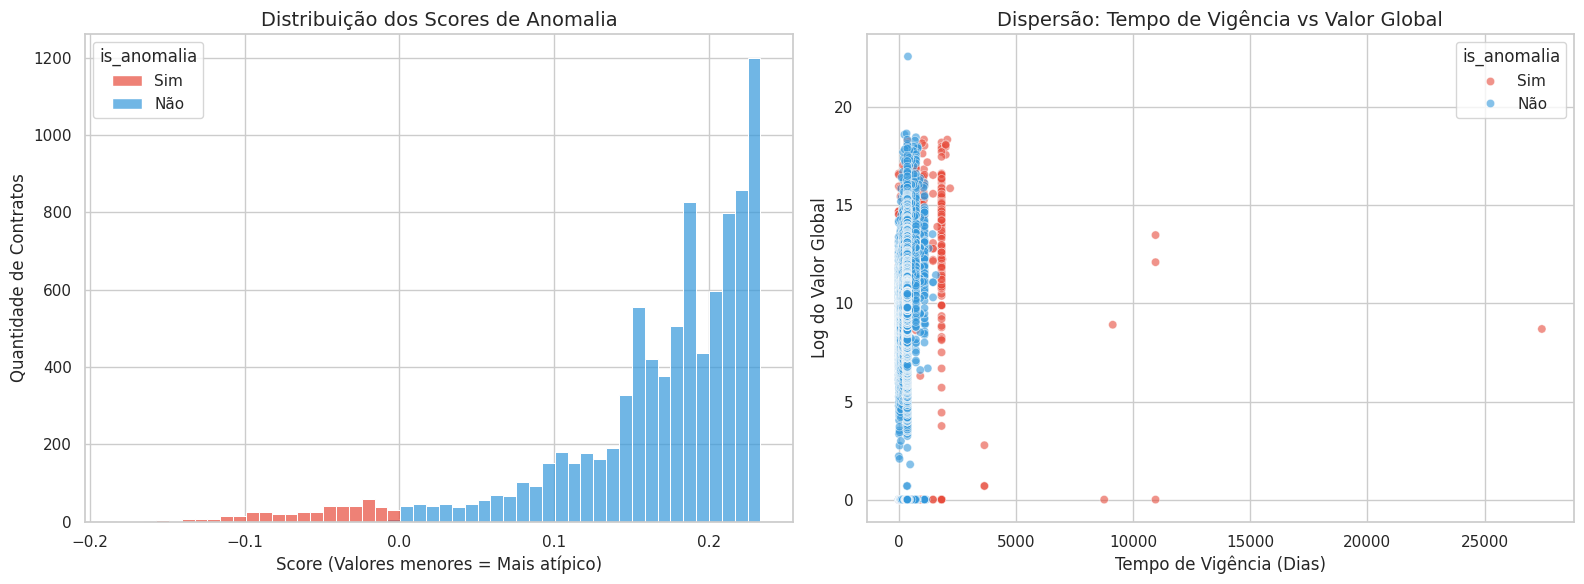


✅ Gráficos gerados e salvos com sucesso em: /content/projeto_pncp/resultados/graficos/analise_anomalias_mt.png


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PASTA_GRAFICOS = Path("/content/projeto_pncp/resultados/graficos")
PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)

# Configurando o estilo visual
sns.set_theme(style="whitegrid")

# Criando uma figura com dois subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Distribuição de Scores
sns.histplot(
    data=df_scored,
    x='score_anomalia',
    hue='is_anomalia',
    bins=50,
    palette={'Sim': '#e74c3c', 'Não': '#3498db'},
    ax=axes[0],
    alpha=0.7
)
axes[0].set_title('Distribuição dos Scores de Anomalia', fontsize=14)
axes[0].set_xlabel('Score (Valores menores = Mais atípico)', fontsize=12)
axes[0].set_ylabel('Quantidade de Contratos', fontsize=12)

# Gráfico 2: Tempo de Vigência vs Valor Global (Log)
sns.scatterplot(
    data=df_scored,
    x='tempo_vigencia_dias',
    y='log_valor_global',
    hue='is_anomalia',
    palette={'Sim': '#e74c3c', 'Não': '#3498db'},
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title('Dispersão: Tempo de Vigência vs Valor Global', fontsize=14)
axes[1].set_xlabel('Tempo de Vigência (Dias)', fontsize=12)
axes[1].set_ylabel('Log do Valor Global', fontsize=12)

plt.tight_layout()

# Salvando o gráfico
caminho_graficos = PASTA_GRAFICOS / "analise_anomalias_mt.png"
plt.savefig(caminho_graficos, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✅ Gráficos gerados e salvos com sucesso em: {caminho_graficos}")

## Etapa 18: Explicabilidade do Modelo (SHAP)

Aplicaremos a biblioteca SHAP para interpretar as decisões do modelo `Isolation Forest`. Isso nos ajudará a entender quais características (features) foram mais determinantes para que os contratos fossem classificados como atípicos.

In [11]:
!pip install -q shap

Calculando valores SHAP (isso pode levar alguns segundos)...


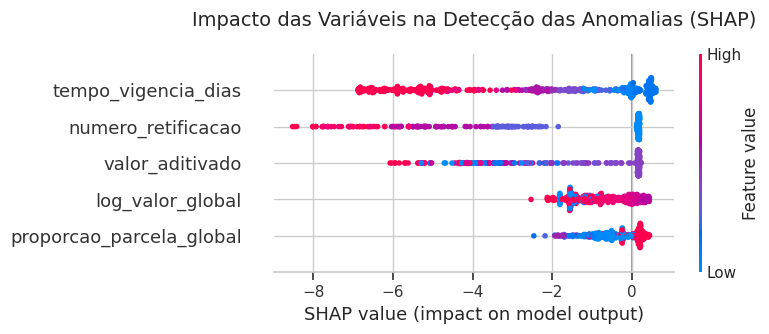


✅ Gráfico de explicabilidade global gerado e salvo em: /content/projeto_pncp/resultados/graficos/shap_summary_anomalias.png


In [12]:
import shap
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Filtrando apenas os contratos anômalos ordenados (do mais atípico para o menos)
df_anomalias = df_scored[df_scored['is_anomalia'] == 'Sim'].copy()
X_anomalias = df_anomalias[colunas_modelo]

# Precisamos padronizar esses dados da mesma forma que fizemos no treinamento
X_anomalias_scaled = scaler.transform(X_anomalias)

# Inicializando o TreeExplainer do SHAP para o Isolation Forest
# O Isolation Forest é baseado em árvores, então o TreeExplainer é o mais adequado e rápido
explainer = shap.TreeExplainer(modelo_if)

# Calculando os valores SHAP para as anomalias
print("Calculando valores SHAP (isso pode levar alguns segundos)...")
shap_values = explainer.shap_values(X_anomalias_scaled)

# Gerando o Gráfico de Resumo (Summary Plot)
# Ele mostra a importância da variável e a direção do impacto
plt.figure(figsize=(10, 6))
plt.title("Impacto das Variáveis na Detecção das Anomalias (SHAP)", fontsize=14, pad=20)
shap.summary_plot(shap_values, X_anomalias, plot_type="dot", show=False)

# Salvando o gráfico
caminho_shap = PASTA_GRAFICOS / "shap_summary_anomalias.png"
plt.savefig(caminho_shap, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✅ Gráfico de explicabilidade global gerado e salvo em: {caminho_shap}")

## Etapa 19: Geração do Ranking Final de Anomalias

Consolidação dos resultados do modelo em um formato amigável para auditoria. Apenas os contratos classificados como anômalos são incluídos, ordenados pelo risco (score).

In [13]:
import pandas as pd
from pathlib import Path

PASTA_TABELAS = Path("/content/projeto_pncp/resultados/tabelas")
PASTA_TABELAS.mkdir(parents=True, exist_ok=True)

# 1. Filtrar apenas as anomalias detectadas
df_ranking = df_scored[df_scored['is_anomalia'] == 'Sim'].copy()

# 2. Selecionar colunas de interesse para a auditoria
colunas_ranking = [
    'score_anomalia',
    'numero_controle_pncp',
    'data_assinatura',
    'orgao_razao_social',
    'nome_municipio',
    'nome_razao_social_fornecedor',
    'objeto_contrato',
    'valor_global',
    'tempo_vigencia_dias',
    'numero_retificacao',
    'valor_aditivado'
]

df_ranking = df_ranking[colunas_ranking]

# 3. Ordenar do mais anômalo (menor score) para o menos anômalo
df_ranking = df_ranking.sort_values(by='score_anomalia', ascending=True)

# 4. Renomear colunas para apresentação
df_ranking = df_ranking.rename(columns={
    'score_anomalia': 'Score de Risco (Anomalia)',
    'numero_controle_pncp': 'ID PNCP',
    'data_assinatura': 'Data de Assinatura',
    'orgao_razao_social': 'Órgão Contratante',
    'nome_municipio': 'Município',
    'nome_razao_social_fornecedor': 'Fornecedor',
    'objeto_contrato': 'Objeto do Contrato',
    'valor_global': 'Valor Global (R$)',
    'tempo_vigencia_dias': 'Vigência (Dias)',
    'numero_retificacao': 'Qtd. Retificações',
    'valor_aditivado': 'Valor Aditivado (R$)'
})

print(f"--- RANKING DE ANOMALIAS: TOP 10 ---")
display(df_ranking.head(10))

# 5. Exportar para CSV e Excel
caminho_csv = PASTA_TABELAS / "ranking_anomalias_mt.csv"
caminho_excel = PASTA_TABELAS / "ranking_anomalias_mt.xlsx"

df_ranking.to_csv(caminho_csv, index=False, sep=';', encoding='utf-8-sig')
df_ranking.to_excel(caminho_excel, index=False)

print(f"\n✅ Ranking gerado com sucesso ({len(df_ranking)} contratos)!")
print(f"📁 Salvo em CSV: {caminho_csv}")
print(f"📁 Salvo em Excel: {caminho_excel}")

--- RANKING DE ANOMALIAS: TOP 10 ---


,Score de Risco (Anomalia),ID PNCP,Data de Assinatura,Órgão Contratante,Município,Fornecedor,Objeto do Contrato,Valor Global (R$),Vigência (Dias),Qtd. Retificações,Valor Aditivado (R$)
0,-0.182255,03533064000146-2-000168/2025,2025-12-19,MUNICIPIO DE CUIABA,Cuiabá,BANCO DO BRASIL S.A.,Centralização pelo contratante no Banco do Bra...,81000000.00,1826.0,0,81000000.00
1,-0.173937,58290502000184-2-000002/2026,2026-01-05,SECRETARIA DE ESTADO DE FAZENDA DE MATO GROSSO,Cuiabá,BANCO ITAÚ UNIBANCO S/A,Contratação de serviço especializado d...,64794556.21,1826.0,1,5989803.80
3,-0.153963,03533064000146-2-000301/2026,2026-08-14,MUNICIPIO DE CUIABA,Cuiabá,HOSPITAL OTORRINO LTDA,Credenciamento de pessoas jurídicas para ...,13264744.26,1826.0,0,13264744.26
2,-0.153963,03533064000146-2-000340/2026,2026-08-28,MUNICIPIO DE CUIABA,Cuiabá,HBENTO SERVIÇOS EM SAUDE,Credenciamento de pessoas jurídicas para ...,13173221.23,1826.0,0,13173221.23
4,-0.150188,03533064000146-2-000328/2026,2026-08-26,MUNICIPIO DE CUIABA,Cuiabá,SANTA MARIA EMPREENDIMENTOS E PARTICIPAÇÕES S/A,O objeto do presente contrato é a locaç...,15360000.00,1461.0,0,15360000.00
5,-0.149332,03535606000110-2-000264/2025,2025-12-29,TRIBUNAL DE JUSTICA DO ESTADO DE MATO GROSSO,Cuiabá,IMPERIAL COMERCIO E SERVICOS TECNOLOGICOS LTDA,Contratação de Solução de Expansão de Processa...,93720324.11,2071.0,2,0.00
6,-0.147791,03533064000146-2-000276/2026,2026-07-28,MUNICIPIO DE CUIABA,Cuiabá,CMO - CENTRO MATOGROSSENSE DE OFTALMOLOGIA LTDA,Credenciamento de pessoas jurídicas para ...,10198153.20,1826.0,0,10198153.20
7,-0.146339,15024003000132-2-000085/2025,2025-10-17,MUNICIPIO DE SINOP,Sinop,SIG TEC SISTEMAS DE INFORMACOES GEOGRAFICAS LTDA,SIG TEC SISTEMAS DE INFORMACOES GEOGRAFICAS LTDA,0.00,1826.0,0,-7584000.00
8,-0.142580,24772246000140-2-000088/2026,2026-04-22,MUNICIPIO DE LUCAS DO RIO VERDE,Lucas do Rio Verde,L. C. ORTH LTDA,CREDENCIAMENTO DESTINADO A EMPRESAS QUE TENHAM...,93950969.60,1075.0,0,93950969.59
9,-0.138934,15024003000132-2-000096/2025,2025-11-10,MUNICIPIO DE SINOP,Sinop,SERVICO FEDERAL DE PROCESSAMENTO DE DADOS (SER...,CONTRATAÇÃO DE EMPRESA PARA PRESTAÇÃO DOS SERV...,0.00,1826.0,0,-6327000.00



✅ Ranking gerado com sucesso (451 contratos)!
📁 Salvo em CSV: /content/projeto_pncp/resultados/tabelas/ranking_anomalias_mt.csv
📁 Salvo em Excel: /content/projeto_pncp/resultados/tabelas/ranking_anomalias_mt.xlsx


## Etapa 20: Análise Detalhada de Casos (Investigação)

Nesta etapa, simulamos o trabalho de um auditor avaliando o contrato de maior risco apontado pelo modelo. Geramos uma "ficha de investigação" com os dados reais do contrato e utilizamos os valores do SHAP locais para entender de forma transparente o que tornou *este* contrato específico tão anômalo perante o algoritmo.

In [14]:
import pandas as pd
import numpy as np

# Selecionando o contrato de maior risco (posição 0 do ranking)
contrato_top1 = df_ranking.iloc[0]

print("="*80)
print("🔍 FICHA DE INVESTIGAÇÃO: CASO #1 (Maior Risco Absoluto)")
print("="*80)
print(f"ID PNCP          : {contrato_top1['ID PNCP']}")
print(f"Órgão Contratante: {contrato_top1['Órgão Contratante']} ({contrato_top1['Município']})")
print(f"Fornecedor       : {contrato_top1['Fornecedor']}")
print(f"Data Assinatura  : {contrato_top1['Data de Assinatura']}")
print(f"Objeto           : {contrato_top1['Objeto do Contrato']}")
print("-" * 80)
print("⚠️ INDICADORES FINANCEIROS E TEMPORAIS:")

# Formatando moeda para o padrão brasileiro (R$ 1.000,00)
valor_global_fmt = f"R$ {contrato_top1['Valor Global (R$)']:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')
valor_adit_fmt = f"R$ {contrato_top1['Valor Aditivado (R$)']:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')

print(f"Valor Global     : {valor_global_fmt}")
print(f"Valor Aditivado  : {valor_adit_fmt}")
print(f"Tempo de Vigência: {contrato_top1['Vigência (Dias)']} dias (aprox. {contrato_top1['Vigência (Dias)']/365:.1f} anos)")
print(f"Retificações     : {contrato_top1['Qtd. Retificações']}")
print("="*80)

# Extraindo a explicação matemática (SHAP local) para ESTE contrato
# A base X_anomalias já está ordenada do mais anômalo para o menos, então o índice 0 é o nosso alvo
impactos_caso1 = pd.DataFrame({
    'Atributo (Feature)': colunas_modelo,
    'Valor Real do Contrato': X_anomalias.iloc[0].values,
    'Impacto SHAP (Quanto mais negativo, mais puxa p/ anomalia)': shap_values[0]
})

# Ordenando do fator mais agravante (menor valor SHAP) para o menos
impactos_caso1 = impactos_caso1.sort_values(by='Impacto SHAP (Quanto mais negativo, mais puxa p/ anomalia)', ascending=True).reset_index(drop=True)

print("\n🧠 MOTIVOS DA DETECÇÃO SEGUNDO O MODELO (Explicabilidade Local):")
display(impactos_caso1)

🔍 FICHA DE INVESTIGAÇÃO: CASO #1 (Maior Risco Absoluto)
ID PNCP          : 03533064000146-2-000168/2025
Órgão Contratante: MUNICIPIO DE CUIABA (Cuiabá)
Fornecedor       : BANCO DO BRASIL S.A.
Data Assinatura  : 2025-12-19
Objeto           : Centralização pelo contratante no Banco do Brasil, de 100% (cem por cento) dos créditos provenientes da folha de pagamento gerada pelo contratante.
--------------------------------------------------------------------------------
⚠️ INDICADORES FINANCEIROS E TEMPORAIS:
Valor Global     : R$ 81.000.000,00
Valor Aditivado  : R$ 81.000.000,00
Tempo de Vigência: 1826.0 dias (aprox. 5.0 anos)
Retificações     : 0

🧠 MOTIVOS DA DETECÇÃO SEGUNDO O MODELO (Explicabilidade Local):


,Atributo (Feature),Valor Real do Contrato,"Impacto SHAP (Quanto mais negativo, mais puxa p/ anomalia)"
0,valor_aditivado,8.100000e+07,-4.148114
1,tempo_vigencia_dias,1.826000e+03,-3.756036
2,log_valor_global,1.820996e+01,-1.612443
3,proporcao_parcela_global,1.000000e+00,0.047318
4,numero_retificacao,0.000000e+00,0.125663


## Etapa 21: Simulação de Impacto Operacional (Priorização de Auditoria)

Criação de uma matriz de priorização que divide as anomalias detectadas em faixas de risco (Alta, Média, Baixa), permitindo direcionar o esforço humano de auditoria e mensurar o volume financeiro coberto por cada faixa.

--- MATRIZ DE PRIORIZAÇÃO DE AUDITORIA ---


,Prioridade de Auditoria,Qtd_Contratos,Valor Global Formatado
0,Alta (Top 10%),46,"R$ 760.476.619,64"
1,Média (Top 10-40%),135,"R$ 958.201.536,92"
2,Baixa (Restante),270,"R$ 793.669.576,50"


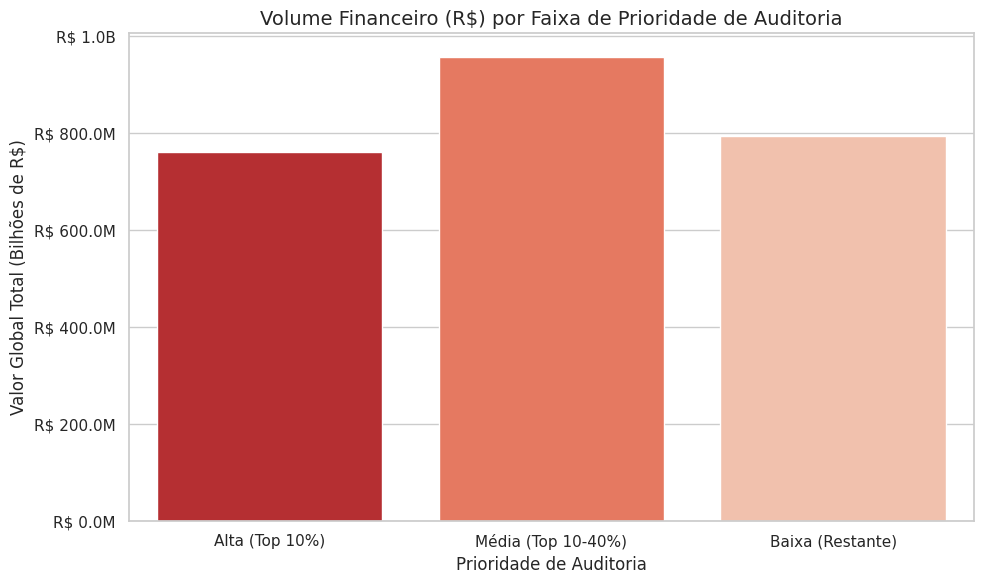


✅ Análise de impacto gerada! Gráfico salvo em: /content/projeto_pncp/resultados/graficos/impacto_operacional.png


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Utilizando o df_ranking que já está ordenado pelo maior risco (menor score)
df_simulacao = df_ranking.copy()

# Criando faixas de prioridade baseadas na posição do ranking (percentis)
n_total = len(df_simulacao)
df_simulacao['Prioridade de Auditoria'] = pd.qcut(
    np.arange(n_total),
    q=[0, 0.1, 0.4, 1.0],
    labels=['Alta (Top 10%)', 'Média (Top 10-40%)', 'Baixa (Restante)']
)

# Resumo Financeiro e Operacional
resumo_auditoria = df_simulacao.groupby('Prioridade de Auditoria', observed=False).agg(
    Qtd_Contratos=('ID PNCP', 'count'),
    Valor_Global_Total=('Valor Global (R$)', 'sum')
).reset_index()

# Formatando valores para exibição na tabela
resumo_auditoria['Valor Global Formatado'] = resumo_auditoria['Valor_Global_Total'].apply(
    lambda x: f"R$ {x:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')
)

print("--- MATRIZ DE PRIORIZAÇÃO DE AUDITORIA ---")
display(resumo_auditoria[['Prioridade de Auditoria', 'Qtd_Contratos', 'Valor Global Formatado']])

# Visualização do Impacto Financeiro
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=resumo_auditoria, x='Prioridade de Auditoria', y='Valor_Global_Total', hue='Prioridade de Auditoria', palette='Reds_r', legend=False)
plt.title('Volume Financeiro (R$) por Faixa de Prioridade de Auditoria', fontsize=14)
plt.xlabel('Prioridade de Auditoria', fontsize=12)
plt.ylabel('Valor Global Total (Bilhões de R$)', fontsize=12)

# Formatando o eixo Y para Bilhões/Milhões para ficar legível
def format_moeda(x, pos):
    return f'R$ {x/1e9:.1f}B' if x >= 1e9 else f'R$ {x/1e6:.1f}M'
ax.yaxis.set_major_formatter(FuncFormatter(format_moeda))

plt.tight_layout()
caminho_grafico_impacto = PASTA_GRAFICOS / "impacto_operacional.png"
plt.savefig(caminho_grafico_impacto, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✅ Análise de impacto gerada! Gráfico salvo em: {caminho_grafico_impacto}")

## Etapa 22: Conclusão do Projeto e Relatório Final

Chegamos ao fim do nosso pipeline de Ciência de Dados aplicado à auditoria governamental. Abaixo, o resumo executivo dos achados para inclusão no trabalho acadêmico ou relatório de auditoria.

### 🎯 Objetivo Alcançado
O projeto desenvolveu com sucesso um sistema não supervisionado para identificar sinais de risco em contratos públicos do Estado de Mato Grosso, extraídos do Portal Nacional de Contratações Públicas (PNCP).

### 🔬 Metodologia
1. **Coleta e Limpeza**: Os dados brutos foram filtrados para o estado de MT (janela de 12 meses, de Set/2025 a Ago/2026), resultando em 9.021 contratos válidos.
2. **Engenharia de Atributos**: Criamos variáveis explicativas focadas em tempo (dias de vigência), valor aditivado e proporção das parcelas.
3. **Modelagem**: O algoritmo *Isolation Forest* foi treinado para isolar os 5% de contratos mais atípicos do ponto de vista matemático.
4. **Explicabilidade**: A biblioteca *SHAP* permitiu entender que altos valores aditivados, prazos de vigência muito longos e altos valores globais foram os principais fatores de anomalia.

### 📈 Principais Resultados
- **451 contratos** foram classificados como anômalos.
- O **Caso #1** (maior risco algorítmico) identificou um contrato de R$ 81 Milhões, com vigência de 5 anos (1.826 dias).
- A **Matriz de Priorização** demonstrou que focar a auditoria humana apenas nos **Top 10% mais anômalos (46 contratos)** permite cobrir o risco de **R$ 760 milhões** em recursos públicos.

*Nota: A atipicidade matemática não comprova fraude, mas atua como um "radar" essencial para direcionar os recursos limitados de controle interno e auditoria.*

## Etapa 23: Empacotamento e Download dos Resultados

Nesta última célula, vamos compactar a pasta `resultados` (que contém nossos dicionários, gráficos, tabelas e modelos) em um arquivo `.zip` e baixá-lo automaticamente.

In [18]:
import shutil
from google.colab import files
from pathlib import Path

PASTA_RESULTADOS = Path("/content/projeto_pncp/resultados")
ARQUIVO_ZIP = "/content/resultados_pncp_mt.zip"

print("Empacotando os resultados do projeto...")
# Cria o arquivo ZIP contendo toda a pasta de resultados
shutil.make_archive(ARQUIVO_ZIP.replace('.zip', ''), 'zip', PASTA_RESULTADOS)

print(f"\n✅ Arquivo ZIP criado com sucesso: {ARQUIVO_ZIP}")
print("Iniciando o download automático...")

# Aciona o download para a máquina local do usuário
files.download(ARQUIVO_ZIP)


Empacotando os resultados do projeto...

✅ Arquivo ZIP criado com sucesso: /content/resultados_pncp_mt.zip
Iniciando o download automático...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Etapa 24: Bônus - Refatoração Metodológica (Auditoria de Código)

Nesta seção, aplicamos as correções identificadas na revisão do código para tornar o modelo viável para produção (alerta em tempo real):
* **Sem Data Leakage**: Remoção de variáveis que indicam o futuro do contrato (aditivos e retificações).
* **Imputação Inteligente**: Uso da mediana em vez de valores arbitrários (`-1`) que confundem modelos baseados em distância.
* **Contaminação Dinâmica**: Deixando o Isolation Forest identificar automaticamente a fronteira do que é anômalo.

In [20]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings('ignore')

PASTA_TRATADOS = Path("/content/projeto_pncp/dados_tratados")
df_refat = pd.read_parquet(PASTA_TRATADOS / "contratos_mt_12m_limpo.parquet")

print("1. Engenharia de Atributos Segura (Sem Vazamento do Futuro)...")
# Tempo de vigência usando Imputação pela Mediana (Correção 1)
df_refat['dt_inicio'] = pd.to_datetime(df_refat['data_vigencia_inicio'], errors='coerce')
df_refat['dt_fim'] = pd.to_datetime(df_refat['data_vigencia_fim'], errors='coerce')
df_refat['tempo_vigencia_dias'] = (df_refat['dt_fim'] - df_refat['dt_inicio']).dt.days

imputer = SimpleImputer(strategy='median')
df_refat['tempo_vigencia_dias'] = imputer.fit_transform(df_refat[['tempo_vigencia_dias']])

# Variáveis Financeiras no momento da assinatura (Correções 2 e 4)
df_refat['log_valor_global'] = np.log1p(df_refat['valor_global'].clip(lower=0))
df_refat['proporcao_parcela_global'] = np.where(
    df_refat['valor_global'] > 0,
    df_refat['valor_parcela'] / df_refat['valor_global'],
    0
)

print("2. Treinamento do Modelo Robusto...")
# As variáveis de aditivo e retificações FORAM REMOVIDAS para evitar Data Leakage
features_seguras = ['tempo_vigencia_dias', 'log_valor_global', 'proporcao_parcela_global']
X_seguro = df_refat[features_seguras].copy()

scaler = StandardScaler()
X_seguro_scaled = scaler.fit_transform(X_seguro)

# Modelagem Robusta: contamination='auto' (Correção 3)
modelo_robusto = IsolationForest(n_estimators=200, contamination='auto', random_state=42, n_jobs=-1)
modelo_robusto.fit(X_seguro_scaled)

# Análise de Scores e Previsões
df_refat['score_anomalia_novo'] = modelo_robusto.decision_function(X_seguro_scaled)
df_refat['is_anomalia_novo'] = np.where(modelo_robusto.predict(X_seguro_scaled) == -1, 'Sim', 'Não')

# Ordenação
df_refat = df_refat.sort_values(by='score_anomalia_novo', ascending=True).reset_index(drop=True)

qtd_anomalias = len(df_refat[df_refat['is_anomalia_novo'] == 'Sim'])
pct_anomalias = (qtd_anomalias / len(df_refat)) * 100

print("\n--- RESULTADOS DO MODELO REFATORADO (TEMPO REAL) ---")
print(f"Total analisado: {len(df_refat)}")
print(f"Anomalias detectadas (Automático): {qtd_anomalias} ({pct_anomalias:.2f}% da base)\n")

display(df_refat[df_refat['is_anomalia_novo'] == 'Sim'][['numero_controle_pncp', 'valor_global', 'tempo_vigencia_dias', 'score_anomalia_novo']].head(10))


1. Engenharia de Atributos Segura (Sem Vazamento do Futuro)...
2. Treinamento do Modelo Robusto...

--- RESULTADOS DO MODELO REFATORADO (TEMPO REAL) ---
Total analisado: 9021
Anomalias detectadas (Automático): 1879 (20.83% da base)



,numero_controle_pncp,valor_global,tempo_vigencia_dias,score_anomalia_novo
0,03347101000121-2-000242/2025,0.01,1825.0,-0.251113
1,00509968000148-2-002390/2026,0.01,1826.0,-0.248576
2,00509968000148-2-000122/2026,0.01,1826.0,-0.248576
3,00509968000148-2-002796/2025,0.01,1826.0,-0.248576
4,00509968000148-2-003556/2025,0.01,1826.0,-0.248576
5,00509968000148-2-004076/2025,0.01,1826.0,-0.248576
6,00509968000148-2-004079/2025,0.01,1826.0,-0.248576
7,00509968000148-2-004078/2025,0.01,1826.0,-0.248576
8,00509968000148-2-002727/2025,0.01,1826.0,-0.248576
9,00509968000148-2-002741/2025,0.01,1826.0,-0.248576
